Name - Vanshika Chauhan

Course - B Tech CSE 3rd year

Subject - Computer Vision

CUID- CU240250953

Labsheet : 2

1:

In [ ]:
import cv2
import numpy as np
import os
from google.colab import files
from IPython.display import display
from PIL import Image

In [ ]:
uploaded = files.upload()

Saving Girl.1.png to Girl.1.png


In [ ]:
filename = list(uploaded.keys())[0]

image = cv2.imread(filename, cv2.IMREAD_UNCHANGED)

if image is None:
    print("Could not load image.")
else:
    print("Image loaded successfully!")

Image loaded successfully!


In [ ]:
if len(image.shape) == 2:
    height, width = image.shape
    channels = 1
else:
    height, width, channels = image.shape

print("Filename     :", filename)
print("Dimensions   :", width, "x", height)
print("Channels     :", channels)
print("Data Type    :", image.dtype)
print("Array Shape  :", image.shape)

Filename     : Screenshot 2026-05-01 095253.png
Dimensions   : 503 x 518
Channels     : 4
Data Type    : uint8
Array Shape  : (518, 503, 4)


In [ ]:
file_size = os.path.getsize(filename)

print("File Size    :", file_size, "bytes")
print("File Size    :", round(file_size / 1024, 2), "KB")

File Size    : 192799 bytes
File Size    : 188.28 KB


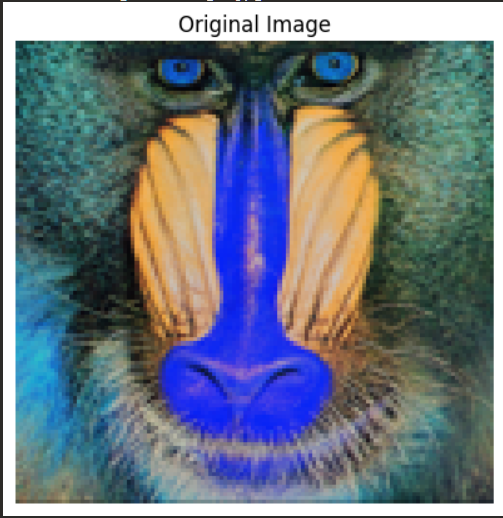

In [ ]:
if channels == 3:
    display_image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    display(Image.fromarray(display_image))
else:
    display(Image.fromarray(image))

2:

In [ ]:
uploaded = files.upload()

filename = list(uploaded.keys())[0]

print("Selected image:", filename)

Saving Screenshot 2026-05-01 112553.png to Screenshot 2026-05-01 112553.png
Selected image: Screenshot 2026-05-01 112553.png


In [ ]:
image = cv2.imread(filename)

if image is None:
    print("Could not load image.")
else:
    print("Image loaded successfully!")
    print("Original shape:", image.shape)

Image loaded successfully!
Original shape: (571, 455, 3)


In [ ]:
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

In [ ]:
print("Grayscale shape:", gray.shape)

Grayscale shape: (571, 455)


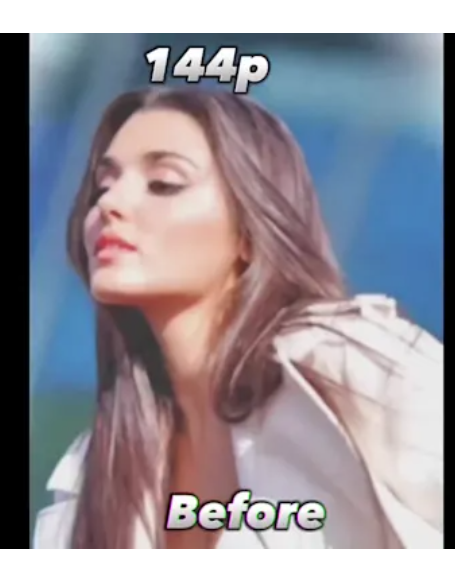

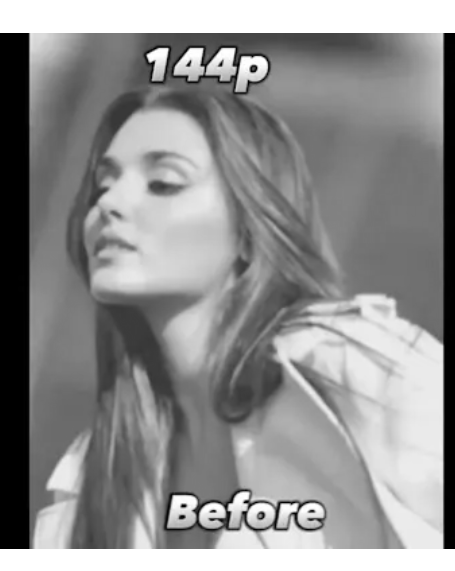

In [ ]:
original_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

display(Image.fromarray(original_rgb))
display(Image.fromarray(gray))

In [ ]:
gray_3channel = cv2.cvtColor(gray, cv2.COLOR_GRAY2BGR)

In [ ]:
comparison = np.hstack((image, gray_3channel))

In [ ]:
output_filename = "colour_grayscale_comparison.jpg"

cv2.imwrite(output_filename, comparison)

print("Saved:", output_filename)

Saved: colour_grayscale_comparison.jpg


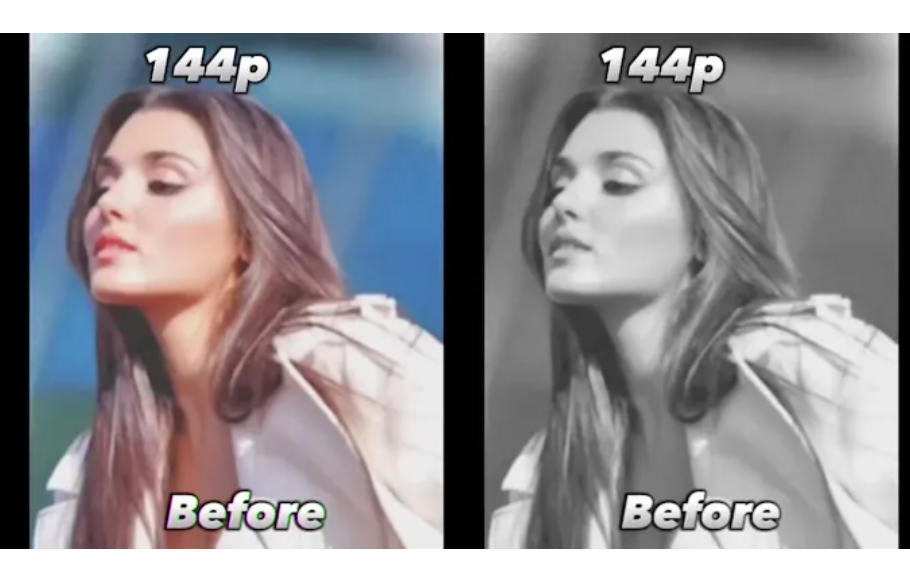

In [ ]:
comparison_rgb = cv2.cvtColor(comparison, cv2.COLOR_BGR2RGB)

display(Image.fromarray(comparison_rgb))

 3:


In [ ]:
image = cv2.imread(filename)

if image is None:
    print("Could not load image.")

else:

    print("Image loaded successfully!")
    print("Image shape:", image.shape)

    # ---------------------------------------
    # 3. Save in three formats
    # ---------------------------------------

    jpg_file = "converted_image.jpg"
    png_file = "converted_image.png"
    bmp_file = "converted_image.bmp"

    cv2.imwrite(jpg_file, image)
    cv2.imwrite(png_file, image)
    cv2.imwrite(bmp_file, image)



Image loaded successfully!
Image shape: (571, 455, 3)


### 4. Calculate file sizes

In [ ]:
jpg_size = os.path.getsize(jpg_file)
png_size = os.path.getsize(png_file)
bmp_size = os.path.getsize(bmp_file)

jpg_kb = jpg_size / 1024
png_kb = png_size / 1024
bmp_kb = bmp_size / 1024

### 5. Display comparison

In [ ]:
print("\n==============================")
print("     FILE SIZE COMPARISON")
print("==============================")

print(f"JPG : {jpg_kb:.2f} KB")
print(f"PNG : {png_kb:.2f} KB")
print(f"BMP : {bmp_kb:.2f} KB")


     FILE SIZE COMPARISON
JPG : 52.41 KB
PNG : 297.88 KB
BMP : 762.87 KB


### 6. Find smallest

In [ ]:
sizes = {
    "JPG": jpg_kb,
    "PNG": png_kb,
    "BMP": bmp_kb
}

smallest = min(sizes, key=sizes.get)

print("\nSmallest format:", smallest)


Smallest format: JPG


##7.  Photo Negative Generator

In [ ]:
# Calculate the photo negative (complement) of the image
# For an 8-bit image, the negative is 255 - pixel_value
negative_image = 255 - image

print("Negative image shape:", negative_image.shape)

Negative image shape: (571, 455, 3)


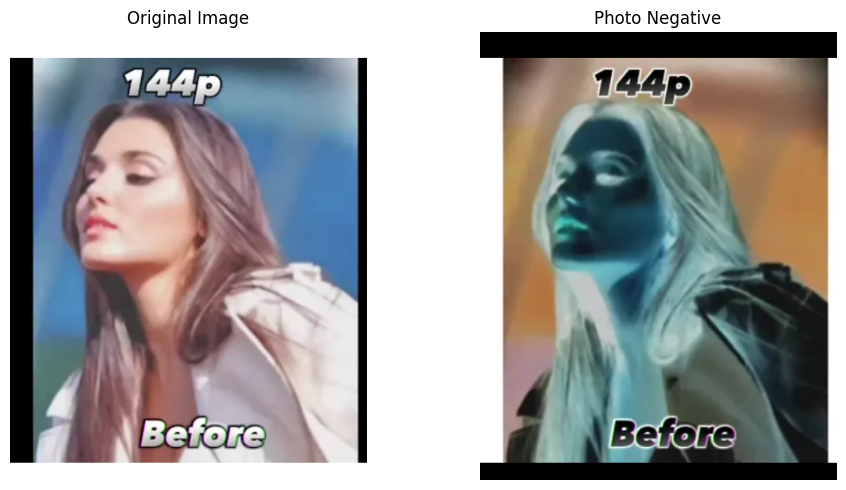

In [ ]:
import matplotlib.pyplot as plt

# Convert images from BGR to RGB for proper display
original_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
negative_rgb = cv2.cvtColor(negative_image, cv2.COLOR_BGR2RGB)

# Display the original and negative images side-by-side
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(original_rgb)
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(negative_rgb)
plt.title('Photo Negative')
plt.axis('off')

plt.tight_layout()
plt.show()

##8.  Batch Image Resizer

This section will demonstrate how to resize multiple images in a batch, preserving their aspect ratio.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
input_folder = '/content/drive/MyDrive/input_images' # Change this to your input folder path
output_folder = '/content/drive/MyDrive/resized_images' # Change this to your output folder path

# Create input and output folders if they don't exist
os.makedirs(input_folder, exist_ok=True)
os.makedirs(output_folder, exist_ok=True)

# --- Placeholder image generation (for demonstration if no images are provided) ---
# This part ensures the script can run even without pre-uploaded images.
if not any(fname.endswith(('.jpg', '.png', '.jpeg')) for fname in os.listdir(input_folder)):
    print(f"No images found in {input_folder}. Generating placeholder images...")
    for i in range(3):
        dummy_image = np.random.randint(0, 256, (np.random.randint(200, 500), np.random.randint(300, 600), 3), dtype=np.uint8)
        cv2.imwrite(os.path.join(input_folder, f'dummy_image_{i+1}.png'), dummy_image)
    print("Placeholder images generated.")
else:
    print(f"Using images from {input_folder}.")


No images found in /content/drive/MyDrive/input_images. Generating placeholder images...
Placeholder images generated.


9. Now, let's define the resizing parameters and process the images.

In [ ]:
target_width = 300  # Set your desired width. If `target_height` is also set, it will be ignored.
# target_height = 200 # You can set target height instead of width if preferred, but not both.

print(f"Resizing images in '{input_folder}' to a width of {target_width} pixels (preserving aspect ratio) and saving to '{output_folder}'.")

for filename in os.listdir(input_folder):
    if filename.lower().endswith(('.png', '.jpg', '.jpeg')):
        img_path = os.path.join(input_folder, filename)
        img = cv2.imread(img_path)

        if img is None:
            print(f"Warning: Could not read image {filename}. Skipping.")
            continue

        # Get original dimensions
        original_height, original_width = img.shape[0], img.shape[1]

        # Calculate new dimensions while preserving aspect ratio
        if 'target_width' in locals() and target_width is not None:
            ratio = target_width / original_width
            new_width = target_width
            new_height = int(original_height * ratio)
        elif 'target_height' in locals() and target_height is not None:
            ratio = target_height / original_height
            new_height = target_height
            new_width = int(original_width * ratio)
        else:
            print(f"Error: Either target_width or target_height must be set for {filename}. Skipping.")
            continue

        # Resize the image
        resized_img = cv2.resize(img, (new_width, new_height), interpolation=cv2.INTER_AREA)

        # Save the resized image to the output folder
        output_filename = f"resized_{filename}"
        output_path = os.path.join(output_folder, output_filename)
        cv2.imwrite(output_path, resized_img)

        print(f"Resized '{filename}' from {original_width}x{original_height} to {new_width}x{new_height} and saved as '{output_filename}'")

print("\nBatch resizing complete!")


Resizing images in '/content/drive/MyDrive/input_images' to a width of 300 pixels (preserving aspect ratio) and saving to '/content/drive/MyDrive/resized_images'.
Resized 'dummy_image_1.png' from 373x455 to 300x365 and saved as 'resized_dummy_image_1.png'
Resized 'dummy_image_2.png' from 306x442 to 300x433 and saved as 'resized_dummy_image_2.png'
Resized 'dummy_image_3.png' from 381x496 to 300x390 and saved as 'resized_dummy_image_3.png'

Batch resizing complete!


## 10. Image Cropping (Region of Interest - ROI)

In [ ]:
# Assuming 'image' variable already holds the loaded image from previous steps
# If not, you might need to load an image first, for example:
# image = cv2.imread(filename)

if 'image' not in locals():
    print("No image loaded. Please run the image loading cells first.")
else:
    print("Using the currently loaded image for cropping.")

Using the currently loaded image for cropping.
